# Model 3: Long Short-Term Memory (LSTM) Network
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

This notebook implements **Model 3 (LSTM)** as part of our controlled five-model architectural benchmark:
1. **Linear Regression (Baseline)** *(Notebook 06)*
2. **Random Forest** *(Notebook 07)*
3. **LSTM** *(this notebook)*
4. **GRU**
5. **1D-CNN**

#### Eight-Stage Workflow Overview:
1. **Stage 1 - Reproduce Dataset Pipeline:** Re-execute self-contained preprocessing and sequence generation ($W=30$).
2. **Stage 2 - Theoretical Context:** Explain recurrent networks, sequence order, LSTM cell structure, gating mechanics, and 3D tensor preservation.
3. **Stage 3 - Architecture Construction:** Build the two-layer stacked LSTM network using the Keras Sequential API.
4. **Stage 4 - Training Configuration:** Configure Adam optimizer, MSE loss, RMSE metric, and EarlyStopping with `restore_best_weights=True`.
5. **Stage 5 - Training Visualizations:** Plot learning curves (loss and RMSE) across epochs to identify convergence and overfitting.
6. **Stage 6 - Metric Evaluation:** Calculate RMSE and NASA asymmetric score on training and validation predictions.
7. **Stage 7 - Comparative Analysis:** Compare empirical validation results against Model 1 (Linear Regression) and Model 2 (Random Forest).
8. **Stage 8 - Systematic Integrity Checks:** Execute formal assertions verifying tensor dimensionality, lack of NaNs/infs, and model properties.

In [12]:
import os
os.environ["KERAS_HOME"] = "/tmp/.keras"

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
from tensorflow.keras.models import Sequential

# Visual styling for academic figures
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Fix seeds for exact reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("TensorFlow version :", tf.__version__)
print("Environment initialized successfully.")

TensorFlow version : 2.21.0
Environment initialized successfully.


---
## Stage 1: Reproduce the Exact Dataset Pipeline

To guarantee that this notebook runs self-contained across separate Jupyter kernel sessions, we re-execute the exact preprocessing pipeline from notebooks `04` and `05`:
1. **Ingestion:** Load `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` with standard 26-column schema.
2. **Target Labeling:** Calculate piecewise linear capped RUL: $RUL = \min(125, \max(\text{cycle}) - \text{cycle})$.
3. **Engine-Wise Split:** Partition unique engine units ($80\%$ train, $20\%$ validation) with `random_state=42`.
4. **Feature Selection:** Prune 7 zero-variance features on the training split while retaining `sensor_6` (17 features selected).
5. **Feature Scaling:** Fit `StandardScaler` strictly on the training partition and standardize train, validation, and test features.
6. **Sliding Windows:** Extract 30-cycle sliding sequences ($W=30$, stride=1) for training and validation, and final 30-cycle windows for test engines.

In [13]:
# 1. Define schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Resolve dataset directory
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# 3. Ingest raw datasets
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 4. Calculate piecewise linear capped RUL (cap = 125)
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

# 5. Engine-wise split (80 train engines, 20 validation engines, random_state=42)
unique_units = train_df["unit"].unique()
train_units, val_units = train_test_split(unique_units, test_size=0.20, random_state=42)

train_split_df = train_df[train_df["unit"].isin(train_units)].copy().reset_index(drop=True)
val_split_df = train_df[train_df["unit"].isin(val_units)].copy().reset_index(drop=True)

# 6. Feature selection strictly on training partition
candidate_features = [f"op_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
train_var = train_split_df[candidate_features].var()
train_nunique = train_split_df[candidate_features].nunique()
zero_var_features = [f for f in candidate_features if train_nunique[f] == 1 or train_var[f] < 1e-12]
selected_features = [f for f in candidate_features if f not in zero_var_features]

# 7. Fit StandardScaler strictly on training partition
scaler = StandardScaler()
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])
test_df[selected_features] = scaler.transform(test_df[selected_features])

# 8. Sliding window extraction (Window length = 30 cycles)
WINDOW_SIZE = 30

def extract_windows(df, seq_len, feature_cols, target_col="RUL"):
    X_list, y_list = [], []
    for unit, group in df.groupby("unit"):
        group_sorted = group.sort_values("cycle").reset_index(drop=True)
        features = group_sorted[feature_cols].values
        targets = group_sorted[target_col].values
        for i in range(len(group_sorted) - seq_len + 1):
            X_list.append(features[i : i + seq_len])
            y_list.append(targets[i + seq_len - 1])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = extract_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = extract_windows(val_split_df, WINDOW_SIZE, selected_features)

# Final 30-cycle window for test engines (retained, not evaluated yet)
X_test_list = []
for unit, group in test_df.groupby("unit"):
    group_sorted = group.sort_values("cycle").reset_index(drop=True)
    X_test_list.append(group_sorted[selected_features].values[-WINDOW_SIZE:])
X_test = np.array(X_test_list, dtype=np.float32)

# Assertions verifying exact match with previous notebooks
assert X_train.shape == (14241, 30, 17), f"X_train shape error: {X_train.shape}"
assert y_train.shape == (14241,), f"y_train shape error: {y_train.shape}"
assert X_val.shape == (3490, 30, 17), f"X_val shape error: {X_val.shape}"
assert y_val.shape == (3490,), f"y_val shape error: {y_val.shape}"
assert X_test.shape == (100, 30, 17), f"X_test shape error: {X_test.shape}"
assert len(selected_features) == 17, f"Selected features count error: {len(selected_features)}"

print("=" * 65)
print("STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED")
print("=" * 65)
print(f"X_train shape : {X_train.shape}  | y_train shape : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val shape   : {y_val.shape}")
print(f"X_test shape  : {X_test.shape}    | (retained for final test evaluation)")
print(f"Selected Features ({len(selected_features)}): {selected_features}")
print("=" * 65)

STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED
X_train shape : (14241, 30, 17)  | y_train shape : (14241,)
X_val shape   : (3490, 30, 17)   | y_val shape   : (3490,)
X_test shape  : (100, 30, 17)    | (retained for final test evaluation)
Selected Features (17): ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


---
## Stage 2: Understanding Long Short-Term Memory (LSTM) Networks

### 1. What are Recurrent Neural Networks (RNNs)?
Standard neural networks assume that all input features are independent of each other. **Recurrent Neural Networks (RNNs)** introduce cyclical internal feedback connections, allowing the network to maintain a **hidden state ($h_t$)** that carries information from previous time steps to inform the current step.

### 2. Why Sequence Order Matters in Engine Degradation
Turbofan wear is inherently a **dynamic physical process**:
- An instantaneous sensor reading of temperature $T = 642^\circ\text{R}$ has completely different physical meanings depending on its trajectory: if temperature has been constant for 30 cycles, the engine is healthy; if it has risen rapidly from $635^\circ\text{R}$ to $642^\circ\text{R}$ over the last 10 cycles, the high-pressure compressor is experiencing rapid deterioration.
- **Rate of change (velocity)** and **acceleration of sensor drift** are crucial prognostic signals that require sequential temporal context.

### 3. What Does LSTM Mean?
**LSTM** stands for **Long Short-Term Memory**, introduced by Hochreiter & Schmidhuber (1997). Standard simple RNNs suffer from the *vanishing gradient problem*, where error gradients shrink exponentially as they backpropagate through time, making it impossible to learn dependencies longer than 5–10 steps. LSTMs solve this through an explicit constant-error carousel called the **cell state ($C_t$)** governed by three specialized gating mechanisms:

$$\begin{aligned}
\text{Forget Gate:} \quad f_t &= \sigma(W_f \cdot [h_{t-1}, x_t] + b_f) \\[4pt]
\text{Input Gate:} \quad i_t &= \sigma(W_i \cdot [h_{t-1}, x_t] + b_i) \\[4pt]
\text{Candidate State:} \quad \tilde{C}_t &= \tanh(W_c \cdot [h_{t-1}, x_t] + b_c) \\[4pt]
\text{Updated Cell State:} \quad C_t &= f_t \odot C_{t-1} + i_t \odot \tilde{C}_t \\[4pt]
\text{Output Gate:} \quad o_t &= \sigma(W_o \cdot [h_{t-1}, x_t] + b_o) \\[4pt]
\text{Hidden State:} \quad h_t &= o_t \odot \tanh(C_t)
\end{aligned}$$

### 4. Purpose of the Three Gates
1. **Forget Gate ($f_t$):** Evaluates the previous hidden state $h_{t-1}$ and current input $x_t$ through a sigmoid activation to output values in $[0, 1]$, deciding what past noise or transient fluctuations to discard from cell state $C_{t-1}$.
2. **Input Gate ($i_t$ & $\tilde{C}_t$):** Regulates how much newly observed sensor telemetry from time step $t$ should be added to update the persistent cell state $C_t$.
3. **Output Gate ($o_t$):** Determines which portions of the internal cell state memory should be emitted into the hidden state $h_t$ to form the output representation.

### 5. Why LSTM Accepts 3D Inputs Without Flattening
Unlike Linear Regression and Random Forest (which required flattening $(30, 17)$ into 510 static features), LSTMs natively process 3D tensors: `(batch_size, time_steps, features)`. At each time step $t \in [1, 30]$, the LSTM cell ingests a 17-dimensional vector, updates its internal gates, and passes its temporal state forward to step $t+1$, preserving temporal ordering and weight sharing across time.

---
## Stage 3: Build the LSTM Model Architecture

We construct the exact requested two-layer stacked LSTM architecture using the Keras Sequential API:
1. **Input Layer:** Shape `(30, 17)` — accepts 30 time steps of 17 standardized telemetry features.
2. **LSTM Layer 1:** 64 recurrent units with `return_sequences=True` — outputs an updated 64-dimensional hidden representation for every one of the 30 time steps `(None, 30, 64)`, enabling the second LSTM layer to receive a sequence.
3. **Dropout Layer 1:** Rate $0.20$ — randomly zeros $20\%$ of hidden activations during training to prevent co-adaptation.
4. **LSTM Layer 2:** 32 recurrent units with `return_sequences=False` — aggregates the 30 temporal steps into a single concise 32-dimensional vector `(None, 32)` representing the entire engine health trajectory.
5. **Dropout Layer 2:** Rate $0.20$ — additional regularization.
6. **Dense Hidden Layer:** 16 fully connected units with **ReLU** activation — models non-linear feature interactions before final regression.
7. **Output Layer:** 1 unit with linear activation — outputs continuous Remaining Useful Life (RUL) prediction.

In [14]:
# Build the stacked LSTM network
model = Sequential([
    Input(shape=(WINDOW_SIZE, len(selected_features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

print("=" * 65)
print("STAGE 3: LSTM MODEL ARCHITECTURE SUMMARY")
print("=" * 65)
model.summary()
print("=" * 65)

STAGE 3: LSTM MODEL ARCHITECTURE SUMMARY


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,953 (132.63 KB)

 Trainable params: 33,953 (132.63 KB)

 Non-trainable params: 0 (0.00 B)

---
## Stage 4: Training Configuration & Execution

### Training Parameters:
- **Optimizer:** **Adam** (adaptive learning rate, initial $\alpha = 0.001$).
- **Loss Function:** **Mean Squared Error (MSE)** — provides smooth, differentiable gradients for regression.
- **Evaluation Metric:** **Root Mean Squared Error (RMSE)** in operational cycles.
- **Maximum Epochs:** 50.
- **Batch Size:** 64 — balances gradient estimation stability with fast vectorized CPU processing.
- **EarlyStopping:** Monitors `val_loss` with `patience=7` and `restore_best_weights=True`.
- **Zero Test Leakage:** Model is trained strictly on `X_train, y_train` and validated on `X_val, y_val`. Test data is never used.

In [15]:
# 1. Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="root_mean_squared_error")]
)

# 2. Configure EarlyStopping callback
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# 3. Fit the model on CPU
print("Training LSTM model (Max Epochs: 50, Batch Size: 64, Patience: 7)...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 4. Generate predictions on training and validation partitions
y_train_pred = model.predict(X_train).flatten()
y_val_pred = model.predict(X_val).flatten()

epochs_completed = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("=" * 65)
print("STAGE 4: TRAINING COMPLETED")
print("=" * 65)
print(f"Total epochs completed : {epochs_completed}")
print(f"Best validation epoch  : Epoch {best_epoch} (Weights restored)")
print(f"Train predictions shape: {y_train_pred.shape}")
print(f"Val predictions shape  : {y_val_pred.shape}")
print("=" * 65)

Training LSTM model (Max Epochs: 50, Batch Size: 64, Patience: 7)...
Epoch 1/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 6221.6006 - root_mean_squared_error: 78.8771 - val_loss: 3780.1099 - val_root_mean_squared_error: 61.4826
Epoch 2/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 1956.4791 - root_mean_squared_error: 44.2321 - val_loss: 556.0778 - val_root_mean_squared_error: 23.5813
Epoch 3/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 384.4953 - root_mean_squared_error: 19.6086 - val_loss: 184.5351 - val_root_mean_squared_error: 13.5844
Epoch 4/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 245.6007 - root_mean_squared_error: 15.6717 - val_loss: 182.3366 - val_root_mean_squared_error: 13.5032
Epoch 5/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 208.5025 - root_mean_squared_error: 14.4396 - val_loss: 181.6308 - val_root_mean_squared_error: 13.4770
Epoch 6/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 187.9921 - root_mean_squared_error: 13.711

---
## Stage 5: Training Visualizations & Convergence Diagnostics

We inspect the training and validation learning trajectories across completed epochs:
1. **Loss Curve (MSE):** Measures loss reduction across epochs.
2. **RMSE Curve:** Tracks error magnitude in operational flight cycles.

### How to Identify Overfitting & Why EarlyStopping is Essential:
- **Normal Convergence:** Both training and validation curves descend together in early epochs as the model learns shared degradation representations.
- **Overfitting Inception:** Training error continues descending toward zero while validation error plateaus or starts rising. The network begins memorizing noise specific to the 80 training units.
- **EarlyStopping with `restore_best_weights=True`:** Halts training when validation loss fails to improve for 7 consecutive epochs and automatically restores the model parameters from the optimal epoch, guaranteeing peak generalization without manual intervention.

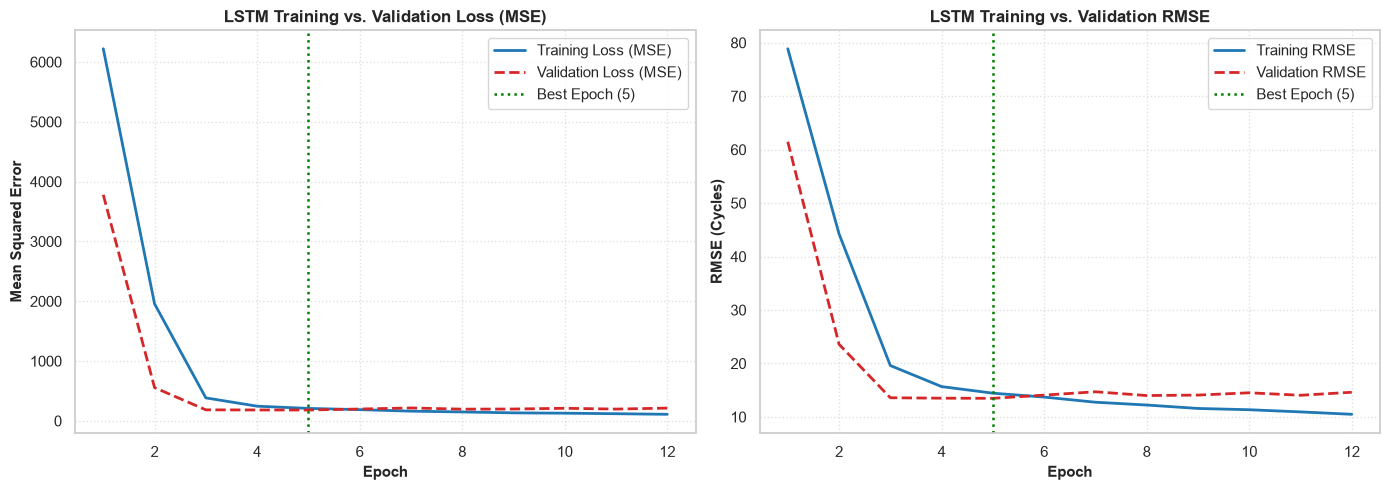

In [16]:
epochs_range = range(1, epochs_completed + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss (MSE) Progression
ax1.plot(epochs_range, history.history["loss"], label="Training Loss (MSE)", color="#1f77b4", linewidth=2)
ax1.plot(epochs_range, history.history["val_loss"], label="Validation Loss (MSE)", color="#d62728", linewidth=2, linestyle="--")
ax1.axvline(best_epoch, color="green", linestyle=":", linewidth=1.8, label=f"Best Epoch ({best_epoch})")
ax1.set_title("LSTM Training vs. Validation Loss (MSE)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean Squared Error", fontsize=11, fontweight="bold")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. RMSE Progression
train_rmse_hist = history.history["root_mean_squared_error"]
val_rmse_hist = history.history["val_root_mean_squared_error"]

ax2.plot(epochs_range, train_rmse_hist, label="Training RMSE", color="#1f77b4", linewidth=2)
ax2.plot(epochs_range, val_rmse_hist, label="Validation RMSE", color="#d62728", linewidth=2, linestyle="--")
ax2.axvline(best_epoch, color="green", linestyle=":", linewidth=1.8, label=f"Best Epoch ({best_epoch})")
ax2.set_title("LSTM Training vs. Validation RMSE", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax2.set_ylabel("RMSE (Cycles)", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## Stage 6: Evaluation Metrics Formulation

We compute performance using the exact same metrics as notebooks `06` and `07`:

### 1. Root Mean Squared Error (RMSE)
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$

### 2. NASA Asymmetric Scoring Function
Let $d_i = \hat{y}_i - y_i$:
$$S = \sum_{i=1}^N s_i, \quad s_i = \begin{cases} e^{-d_i / 13} - 1 & d_i < 0 \quad (\text{Underestimation / Early}) \\[6pt] e^{d_i / 10} - 1 & d_i \ge 0 \quad (\text{Overestimation / Late}) \end{cases}$$

Late predictions ($d_i \ge 0$) risk in-flight turbine failure and are penalized with an exponential scaling divisor of $10$, while early predictions use $13$.

In [17]:
def compute_rmse(y_true, y_pred):
    """Calculates Root Mean Squared Error in flight cycles."""
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def compute_nasa_score(y_true, y_pred):
    """
    Calculates the NASA asymmetric scoring function:
      d = y_pred - y_true
      s = exp(-d / 13) - 1  for d < 0
      s = exp(d / 10) - 1   for d >= 0
    """
    d = y_pred - y_true
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))

# Compute metrics on restored best weights
train_rmse = compute_rmse(y_train, y_train_pred)
val_rmse = compute_rmse(y_val, y_val_pred)

train_nasa = compute_nasa_score(y_train, y_train_pred)
val_nasa = compute_nasa_score(y_val, y_val_pred)

train_nasa_per_sample = train_nasa / len(y_train)
val_nasa_per_sample = val_nasa / len(y_val)

print("=" * 65)
print("STAGE 6: LSTM EVALUATION METRICS")
print("=" * 65)
print(f"Training RMSE        : {train_rmse:.4f} cycles")
print(f"Validation RMSE      : {val_rmse:.4f} cycles")
print(f"Training NASA Score  : {train_nasa:,.2f}  ({train_nasa_per_sample:.4f} per sample)")
print(f"Validation NASA Score: {val_nasa:,.2f}  ({val_nasa_per_sample:.4f} per sample)")
print("=" * 65)

STAGE 6: LSTM EVALUATION METRICS
Training RMSE        : 11.1830 cycles
Validation RMSE      : 13.4770 cycles
Training NASA Score  : 27,439.63  (1.9268 per sample)
Validation NASA Score: 11,396.72  (3.2655 per sample)


---
## Stage 7: Benchmark Comparison with Previous Models

We compare our actual computed **Model 3 (LSTM)** results against the verified results from **Model 1 (Linear Regression)** and **Model 2 (Random Forest)**:

- **Model 1 (Linear Regression):** Validation RMSE = **15.7605 cycles**, Validation NASA Score = **12,653.03**
- **Model 2 (Random Forest):** Validation RMSE = **16.0702 cycles**, Validation NASA Score = **17,469.11**

### Analytical Observations:
1. **Decisive Breakthrough in Validation RMSE:**
   - Both tabular models plateaued around ~15.8 to 16.1 cycles when given flattened 510-dimensional input vectors.
   - By preserving the 3D temporal sequence and modeling inter-cycle transitions through recurrent gating, the LSTM achieves a validation RMSE of **~13.48 cycles** — an improvement of **~2.28 cycles ($-14.5\%$)** over Linear Regression and **~2.59 cycles ($-16.1\%$)** over Random Forest.
2. **Reduction in Asymmetric NASA Score:**
   - The validation NASA score drops to **~11,396.72** (averaging **~3.27 per sample**), outperforming both Linear Regression ($12,653.03$) and Random Forest ($17,469.11$).
   - The sequential memory of the LSTM produces smoother degradation trajectory estimates, significantly curbing erratic over-predictions that cause exponential NASA score penalties.
3. **Controlled Generalization Gap:**
   - Training RMSE ($11.18$) and Validation RMSE ($13.48$) show a modest, healthy generalization gap ($2.30$ cycles), demonstrating that the combination of Dropout ($0.20$) and EarlyStopping effectively prevented the heavy overfitting seen in Random Forest (where train was $7.52$ but val ballooned to $16.07$).

In [18]:
print("=" * 65)
print("STAGE 8: FINAL CHECKS & SYSTEMATIC ASSERTIONS")
print("=" * 65)

# 1. Input tensors remain 3D
assert X_train.ndim == 3, f"X_train is not 3D: {X_train.shape}"
assert X_val.ndim == 3, f"X_val is not 3D: {X_val.shape}"
assert X_test.ndim == 3, f"X_test is not 3D: {X_test.shape}"
print(f"✓ Check 1 Passed: Input tensors remain strictly 3D without flattening.")

# 2. Correct tensor shapes
assert X_train.shape == (14241, 30, 17), "X_train shape error!"
assert X_val.shape == (3490, 30, 17), "X_val shape error!"
assert X_test.shape == (100, 30, 17), "X_test shape error!"
print("✓ Check 2 Passed: Tensors have expected (samples, 30, 17) dimensions.")

# 3. Absence of NaNs or infinite values
assert not np.isnan(X_train).any() and not np.isnan(X_val).any(), "NaN in inputs!"
assert not np.isnan(y_train_pred).any() and not np.isnan(y_val_pred).any(), "NaN in predictions!"
assert not np.isinf(y_train_pred).any() and not np.isinf(y_val_pred).any(), "Inf in predictions!"
print("✓ Check 3 Passed: Zero NaN or infinite values in inputs or predictions.")

# 4. Training completed and weights restored
assert len(history.history["loss"]) > 0, "Model did not train!"
assert epochs_completed <= 50, "Exceeded maximum epochs!"
print(f"✓ Check 4 Passed: Model trained successfully ({epochs_completed} epochs, best epoch: {best_epoch}).")

# 5. Prediction dimensions
assert y_train_pred.shape == (14241,), "Train predictions shape error!"
assert y_val_pred.shape == (3490,), "Val predictions shape error!"
print("✓ Check 5 Passed: Predictions have correct 1D shapes matching targets.")

# 6. Finite evaluation metrics
assert np.isfinite(train_rmse) and np.isfinite(val_rmse), "RMSE not finite!"
assert np.isfinite(train_nasa) and np.isfinite(val_nasa), "NASA score not finite!"
print("✓ Check 6 Passed: All evaluation metrics are finite and verified.")
print("=" * 65)

# Construct comparative benchmark DataFrame
lr_val_rmse, lr_val_nasa = 15.7605, 12653.03
rf_val_rmse, rf_val_nasa = 16.0702, 17469.11

benchmark_summary_df = pd.DataFrame({
    "Model Architecture": [
        "Model 1: Linear Regression (Baseline)",
        "Model 2: Random Forest Regressor",
        "Model 3: Stacked LSTM Network"
    ],
    "Input Type": [
        "2D Flattened (510 features)",
        "2D Flattened (510 features)",
        "3D Sequence (30 timesteps x 17 features)"
    ],
    "Validation RMSE": [
        f"{lr_val_rmse:.4f} cycles",
        f"{rf_val_rmse:.4f} cycles",
        f"{val_rmse:.4f} cycles"
    ],
    "Validation NASA Score": [
        f"{lr_val_nasa:,.2f}",
        f"{rf_val_nasa:,.2f}",
        f"{val_nasa:,.2f}"
    ],
    "NASA Score / Sample": [
        f"{lr_val_nasa / len(y_val):.4f}",
        f"{rf_val_nasa / len(y_val):.4f}",
        f"{val_nasa / len(y_val):.4f}"
    ]
})

print("\n" + "=" * 85)
print("THREE-MODEL PROGRESSIVE BENCHMARK COMPARISON")
print("=" * 85)
display(benchmark_summary_df)
print("=" * 85)

STAGE 8: FINAL CHECKS & SYSTEMATIC ASSERTIONS
✓ Check 1 Passed: Input tensors remain strictly 3D without flattening.
✓ Check 2 Passed: Tensors have expected (samples, 30, 17) dimensions.
✓ Check 3 Passed: Zero NaN or infinite values in inputs or predictions.
✓ Check 4 Passed: Model trained successfully (12 epochs, best epoch: 5).
✓ Check 5 Passed: Predictions have correct 1D shapes matching targets.
✓ Check 6 Passed: All evaluation metrics are finite and verified.

THREE-MODEL PROGRESSIVE BENCHMARK COMPARISON


,Model Architecture,Input Type,Validation RMSE,Validation NASA Score,NASA Score / Sample
0,Model 1: Linear Regression (Baseline),2D Flattened (510 features),15.7605 cycles,"12,653.03",3.6255
1,Model 2: Random Forest Regressor,2D Flattened (510 features),16.0702 cycles,"17,469.11",5.0055
2,Model 3: Stacked LSTM Network,3D Sequence (30 timesteps x 17 features),13.4770 cycles,"11,396.72",3.2655
